# Неделя 02. Python и NumPy на данных энергопотребления

        **Кейс:** сравнить потребление четырёх систем здания за 60 дней, рассчитать стоимость
        и проверить, что векторизованная реализация совпадает с понятным циклом.
        Данные и тарифы синтетические. Здесь важны единицы, форма массивов и правильность расчёта.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import csv
from time import perf_counter

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_02_python_numpy'):
            if candidate.name == 'week_02_python_numpy' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_02_python_numpy


## 1. Список словарей: сначала понятные структуры Python

        Список сохраняет порядок элементов; словарь связывает имя поля со значением.
        CSV хранит текст, поэтому значения нужно преобразовать в числа явно.
        Одна запись — один день. `with` закрывает файл даже при исключении.


In [2]:
with (DATA_DIR / "daily_energy.csv").open(encoding="utf-8", newline="") as handle:
    raw_records = list(csv.DictReader(handle))
records = [{key: float(value) for key, value in row.items()} for row in raw_records]
for record in records:
    record["day"] = int(record["day"])
display(records[:3])
assert len(records) == 60


[{'day': 1,
  'heating_kwh': 45.67,
  'cooling_kwh': 0.0,
  'lighting_kwh': 21.77,
  'equipment_kwh': 59.08,
  'temperature_c': 8.1},
 {'day': 2,
  'heating_kwh': 39.23,
  'cooling_kwh': 4.06,
  'lighting_kwh': 15.36,
  'equipment_kwh': 45.83,
  'temperature_c': 9.5},
 {'day': 3,
  'heating_kwh': 56.6,
  'cooling_kwh': 0.51,
  'lighting_kwh': 20.23,
  'equipment_kwh': 56.07,
  'temperature_c': 10.4}]

## 2. Функция превращает правило в проверяемый объект

        Стоимость равна потреблению, умноженному на тариф. Отрицательное потребление для этого
        упражнения не допускается. Вместо молчаливого исправления входа функция сообщает ошибку.
        Docstring объясняет входы и возвращаемое значение.


In [3]:
def energy_cost(kwh, tariff=25.0):
    "Стоимость в KZT для неотрицательных kWh и тарифа KZT/kWh."
    if kwh < 0 or tariff < 0:
        raise ValueError("Потребление и тариф должны быть неотрицательными")
    return kwh * tariff

assert energy_cost(10, 20) == 200
assert energy_cost(0) == 0
rejected = False
try:
    energy_cost(-1)
except ValueError:
    rejected = True
assert rejected, "Недопустимое отрицательное потребление должно отклоняться"
print("Проверены обычный случай, ноль и недопустимый вход.")


Проверены обычный случай, ноль и недопустимый вход.


## 3. Цикл, comprehension и множества

        Сначала явно суммируем четыре системы. Comprehension удобен для короткого преобразования;
        сложные ветвления лучше оставить в функции. Множество хранит уникальные элементы,
        поэтому подходит для проверки, что номера дней не повторяются.


In [4]:
systems = ["heating_kwh", "cooling_kwh", "lighting_kwh", "equipment_kwh"]
daily_totals_loop = []
for row in records:
    total = 0.0
    for system in systems:
        total += row[system]
    daily_totals_loop.append(total)

daily_totals_comp = [sum(row[name] for name in systems) for row in records]
cold_days = [row["day"] for row in records if row["temperature_c"] < 0]
unique_days = {row["day"] for row in records}
# float-суммирование может отличаться на округление; сравниваем с малым допуском.
assert np.allclose(daily_totals_loop, daily_totals_comp, rtol=1e-12, atol=1e-12)
assert len(unique_days) == len(records)
print("Дни ниже 0 °C:", cold_days)


Дни ниже 0 °C: [42, 43, 44, 45, 46, 47, 49, 50, 51, 57]


## 4. Матрица: строки — дни, столбцы — системы

        $X\in\mathbb{R}^{60\times4}$: $X_{ij}$ — энергия системы $j$ в день $i$.
        `shape` показывает размеры, `dtype` — тип каждого элемента.
        В отличие от вложенных списков, NumPy позволяет применять операции ко всему массиву.


In [5]:
X = np.array([[row[name] for name in systems] for row in records], dtype=np.float64)
days = np.array([row["day"] for row in records])
temperature = np.array([row["temperature_c"] for row in records])
print("Форма X:", X.shape, "| dtype:", X.dtype, "| байт:", X.nbytes)
display(pd.DataFrame(X[:5], columns=systems))
assert X.shape == (60, 4)
assert np.isfinite(X).all() and (X >= 0).all()


Форма X: (60, 4) | dtype: float64 | байт: 1920


,heating_kwh,cooling_kwh,lighting_kwh,equipment_kwh
0,45.67,0.00,21.77,59.08
1,39.23,4.06,15.36,45.83
2,56.60,0.51,20.23,56.07
3,54.30,1.33,19.65,51.46
4,44.55,4.57,19.72,55.85


## 5. Оси и описательная статистика

        `axis=0` сворачивает дни: получаем число для каждой системы.
        `axis=1` сворачивает системы: получаем число для каждого дня.
        Стандартное отклонение с `ddof=1` использует знаменатель n−1;
        для описания всех 60 наблюдений можно явно выбрать `ddof=0`. Не смешивайте соглашения.


In [6]:
daily_totals = X.sum(axis=1)
system_totals = X.sum(axis=0)
summary = pd.DataFrame({"mean_kwh": X.mean(axis=0), "median_kwh": np.median(X, axis=0),
                        "sample_std_kwh": X.std(axis=0, ddof=1),
                        "p90_kwh": np.quantile(X, 0.9, axis=0),
                        "total_kwh": system_totals}, index=systems)
display(summary.round(2))
assert np.allclose(daily_totals, daily_totals_loop)
assert np.isclose(daily_totals.sum(), system_totals.sum())


,mean_kwh,median_kwh,sample_std_kwh,p90_kwh,total_kwh
heating_kwh,57.54,55.64,20.78,87.03,3452.25
cooling_kwh,3.69,0.00,4.92,10.27,221.15
lighting_kwh,19.84,19.80,2.83,23.63,1190.29
equipment_kwh,44.78,45.56,9.48,57.11,2686.93


## 6. Срезы, маски и копии

        Маска — массив True/False, по которому выбираются строки. Базовый срез часто является
        представлением исходной памяти: изменение среза может изменить исходный массив.
        Для независимого эксперимента используйте `.copy()`.


In [7]:
warm_mask = temperature > 12
print("Тёплых дней:", warm_mask.sum())
print("Среднее потребление в тёплые дни:", X[warm_mask].sum(axis=1).mean().round(2))

demo = np.array([10.0, 20.0, 30.0])
view = demo[:2]
view[0] = 99.0
assert demo[0] == 99.0
independent = demo[:2].copy()
independent[0] = -1.0
assert demo[0] == 99.0
print("Срез изменил исходник; копия — нет.")


Тёплых дней: 18
Среднее потребление в тёплые дни: 107.72
Срез изменил исходник; копия — нет.


## 7. Broadcasting: сравниваем формы до вычисления

        Пусть тарифы $t\in\mathbb{R}^{4}$. Произведение `X * t` имеет форму `(60, 4)`:
        NumPy сопоставляет последние размеры, равные либо друг другу, либо 1.
        А `X @ t` даёт вектор из 60 стоимостей: $c_i=\sum_j X_{ij}t_j$.
        Тарифы ниже намеренно различаются как упражнение, а не описание платёжной политики.


In [8]:
tariffs = np.array([24.0, 28.0, 22.0, 26.0])  # KZT / kWh, учебное условие
costs_by_system = X * tariffs
daily_cost = X @ tariffs
assert costs_by_system.shape == X.shape
assert daily_cost.shape == (len(X),)
assert np.allclose(daily_cost, costs_by_system.sum(axis=1))
print("Стоимость за 60 дней:", round(daily_cost.sum(), 2), "KZT")


Стоимость за 60 дней: 185092.76 KZT


## 8. Стандартизация как упражнение с broadcasting

        $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$. Средние и стандартные отклонения имеют форму `(4,)`.
        Если столбец постоянный, деление на ноль нельзя игнорировать: заменим его масштаб на 1.
        **Пока это описание данного набора.** Для ML параметры позже будем вычислять только на train.


In [9]:
mean = X.mean(axis=0)
std = X.std(axis=0, ddof=0)
safe_std = np.where(std == 0, 1.0, std)
Z = (X - mean) / safe_std
assert np.allclose(Z.mean(axis=0), 0, atol=1e-12)
nonconstant = std > 0
assert np.allclose(Z[:, nonconstant].std(axis=0), 1)
reconstructed = Z * safe_std + mean
assert np.allclose(reconstructed, X)
print("Стандартизация и обратное преобразование проверены.")


Стандартизация и обратное преобразование проверены.


## 9. Графики отвечают на разные вопросы

        Линия показывает изменения по порядку дней; scatter показывает связь температуры
        с энергией отопления. Связь специально встроена в генератор. По этому примеру
        нельзя оценивать экономию реального здания.


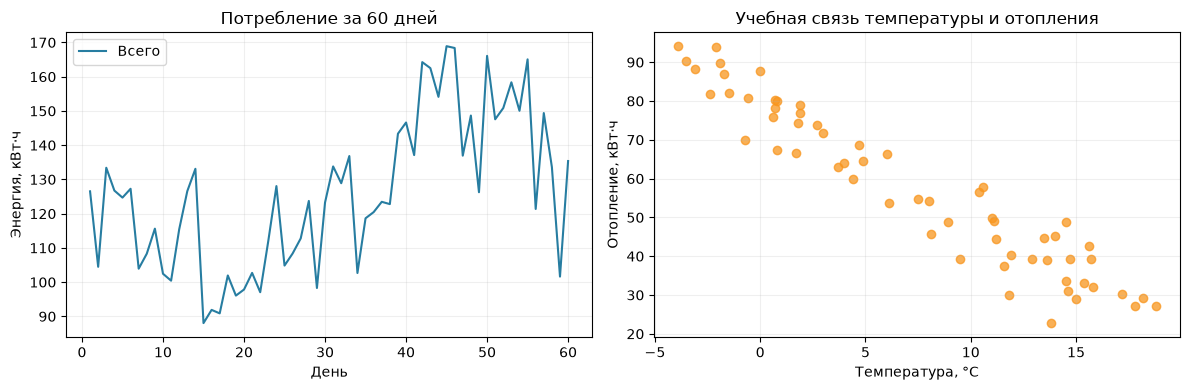

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(days, daily_totals, color="#277DA1", label="Всего")
axes[0].set(xlabel="День", ylabel="Энергия, кВт·ч", title="Потребление за 60 дней")
axes[0].legend()
axes[1].scatter(temperature, X[:, 0], alpha=0.75, color="#F8961E")
axes[1].set(xlabel="Температура, °C", ylabel="Отопление, кВт·ч", title="Учебная связь температуры и отопления")
plt.tight_layout()
plt.show()


## 10. Сравниваем реализации, затем измеряем время

        Правильный ответ важнее скорости. Используем небольшой воспроизводимый массив,
        сравниваем цикл и матричную операцию на одинаковом входе. Одно измерение времени
        зависит от нагрузки машины и не является строгим benchmark; поэтому скорость не проверяется assert.


In [11]:
benchmark_X = np.random.default_rng(SEED).uniform(0, 100, size=(20000, 4))

start = perf_counter()
loop_cost = np.array([sum(value * tariff for value, tariff in zip(row, tariffs))
                      for row in benchmark_X])
loop_seconds = perf_counter() - start
start = perf_counter()
vector_cost = benchmark_X @ tariffs
vector_seconds = perf_counter() - start
assert np.allclose(loop_cost, vector_cost)
display(pd.DataFrame({"implementation": ["Python loop", "NumPy @"],
                      "elapsed_seconds": [loop_seconds, vector_seconds]}))


,implementation,elapsed_seconds
0,Python loop,0.032647
1,NumPy @,0.000134


## 11. Мини-кейс: бюджет и сценарий экономии

        Предположим, только освещение потребляет на 15% меньше, а остальные системы не меняются.
        Сначала копируем массив, затем считаем стоимость тем же тарифом. Это сценарный расчёт
        при заданном допущении, а не прогноз реального эффекта мероприятия.


In [12]:
scenario = X.copy()
scenario[:, 2] *= 0.85
scenario_cost = scenario @ tariffs
saving = daily_cost.sum() - scenario_cost.sum()
analytical_saving = X[:, 2].sum() * tariffs[2] * 0.15
assert np.isclose(saving, analytical_saving)
assert np.array_equal(X[:, [0, 1, 3]], scenario[:, [0, 1, 3]])
print(f"Экономия в учебном сценарии: {saving:,.2f} KZT ({saving / daily_cost.sum():.1%} бюджета).")


Экономия в учебном сценарии: 3,927.96 KZT (2.1% бюджета).


## Обсуждение и перенос навыка

        - Почему `X.mean(axis=0)` имеет 4 числа, а `X.mean(axis=1)` — 60?
        - Какая форма нужна тарифу по дням: `(60,)` или `(60, 1)`, чтобы умножить каждый день отдельно?
        - Почему скорость исполнения не должна заменять проверку размерностей и единиц?
        - Что изменится в стандартизации, если завтра появятся новые наблюдения?

        Домашняя работа: [Homework Week 02](../homework/Homework_Week_02.md).


## Документация и дальнейшее чтение

- [Python: структуры данных](https://docs.python.org/3/tutorial/datastructures.html)
- [NumPy: руководство для начинающих](https://numpy.org/doc/stable/user/absolute_beginners.html)
- [NumPy: broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
